In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score

import warnings
warnings.filterwarnings("ignore")

In [4]:
data = pd.read_csv("drugs.csv")
data

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


In [5]:
# Convertir variables categóricas a números
data_encoded = data.copy()

le_sex = preprocessing.LabelEncoder()
le_bp = preprocessing.LabelEncoder()
le_chol = preprocessing.LabelEncoder()

data_encoded["Sex"] = le_sex.fit_transform(data["Sex"])
data_encoded["BP"] = le_bp.fit_transform(data["BP"])
data_encoded["Cholesterol"] = le_chol.fit_transform(data["Cholesterol"])

data_encoded.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,drugY
1,47,1,1,0,13.093,drugC
2,47,1,1,0,10.114,drugC
3,28,0,2,0,7.798,drugX
4,61,0,1,0,18.043,drugY


In [6]:
# Clasificar medicamentos por origen
data_encoded["Drug"] = data["Drug"].map({
    "drugA": 0,
    "drugB": 0,
    "drugC": 0,
    "drugX": 1,
    "drugY": 1
})

data_encoded["Drug"].value_counts()

Drug
1    145
0     55
Name: count, dtype: int64

In [7]:
# Separar variables predictoras y variable objetivo
X = data_encoded.drop("Drug", axis=1)
y = data_encoded["Drug"]

print("Variables predictoras:")
print(X.head())

print("\nVariable objetivo:")
print(y.head())

Variables predictoras:
   Age  Sex  BP  Cholesterol  Na_to_K
0   23    0   0            0   25.355
1   47    1   1            0   13.093
2   47    1   1            0   10.114
3   28    0   2            0    7.798
4   61    0   1            0   18.043

Variable objetivo:
0    1
1    0
2    0
3    1
4    1
Name: Drug, dtype: int64


In [8]:
# Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (160, 5)
Datos de prueba: (40, 5)


In [9]:
# Estandarizar los datos
scaler = preprocessing.StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos de entrenamiento estandarizados:")
print(X_train_scaled[:5])

Datos de entrenamiento estandarizados:
[[ 0.88939738 -1.06458129  0.12980882 -0.95118973 -0.80380002]
 [ 0.45705143  0.93933644  0.12980882  1.05131497  2.32599149]
 [ 1.38350703  0.93933644  1.35153888  1.05131497 -0.74058598]
 [ 0.1482329  -1.06458129  0.12980882 -0.95118973 -0.85629274]
 [-0.53116788  0.93933644  0.12980882  1.05131497 -0.66734679]]


In [10]:
# Comparar los métodos de optimización
solvers = ["sag", "newton-cg", "liblinear", "saga", "lbfgs"]

resultados = []

for metodo in solvers:
    modelo = LogisticRegression(
        solver=metodo,
        max_iter=5000,
        random_state=42
    )

    modelo.fit(X_train_scaled, y_train)

    precision = modelo.score(X_test_scaled, y_test)

    resultados.append({
        "Solver": metodo,
        "Accuracy": precision
    })

comparacion = pd.DataFrame(resultados)
comparacion

,Solver,Accuracy
0,sag,0.95
1,newton-cg,0.95
2,liblinear,0.95
3,saga,0.95
4,lbfgs,0.95


In [11]:
# Reporte de clasificación con lbfgs
modelo_final = LogisticRegression(
    solver="lbfgs",
    max_iter=5000,
    random_state=42
)

modelo_final.fit(X_train_scaled, y_train)

y_pred = modelo_final.predict(X_test_scaled)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Nacional", "Extranjero"]
))

              precision    recall  f1-score   support

    Nacional       0.91      0.91      0.91        11
  Extranjero       0.97      0.97      0.97        29

    accuracy                           0.95        40
   macro avg       0.94      0.94      0.94        40
weighted avg       0.95      0.95      0.95        40



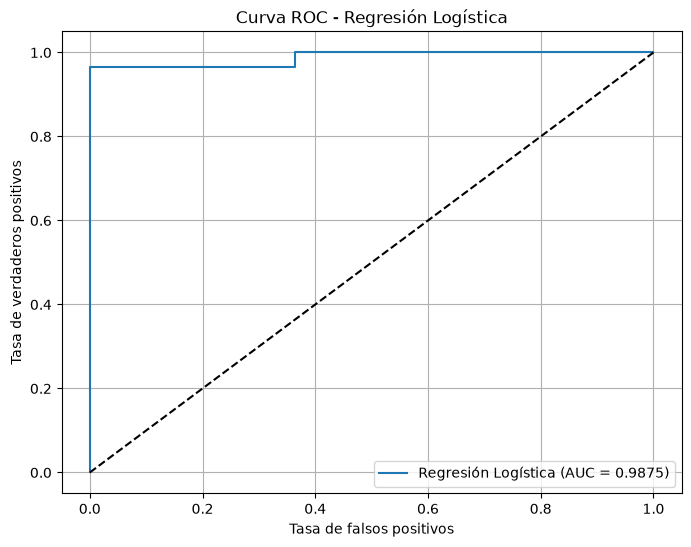

AUC: 0.9874608150470219


In [12]:
# Curva ROC del modelo lbfgs
y_prob = modelo_final.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Regresión Logística (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")

plt.title("Curva ROC - Regresión Logística")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.grid()
plt.show()

print("AUC:", auc)

In [13]:
# Comparar Accuracy y AUC de los 5 solvers
resultados_auc = []

for metodo in solvers:
    modelo = LogisticRegression(
        solver=metodo,
        max_iter=5000,
        random_state=42
    )

    modelo.fit(X_train_scaled, y_train)

    accuracy = modelo.score(X_test_scaled, y_test)
    probabilidades = modelo.predict_proba(X_test_scaled)[:, 1]
    auc_valor = roc_auc_score(y_test, probabilidades)

    resultados_auc.append({
        "Solver": metodo,
        "Accuracy": accuracy,
        "AUC": auc_valor
    })

comparacion_auc = pd.DataFrame(resultados_auc)
comparacion_auc

,Solver,Accuracy,AUC
0,sag,0.95,0.987461
1,newton-cg,0.95,0.987461
2,liblinear,0.95,0.987461
3,saga,0.95,0.987461
4,lbfgs,0.95,0.987461


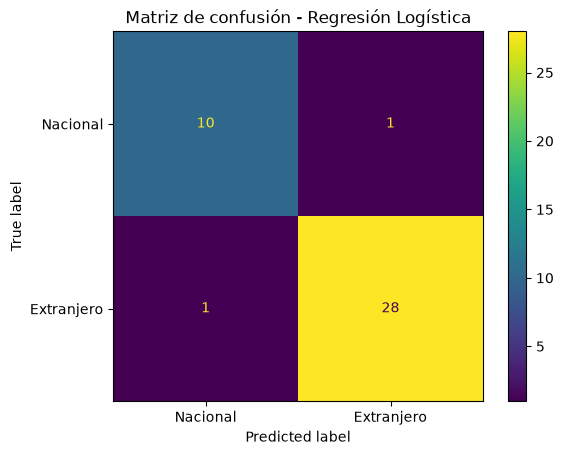

In [14]:
# Matriz de confusión del modelo lbfgs
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Nacional", "Extranjero"]
)

disp.plot()
plt.title("Matriz de confusión - Regresión Logística")
plt.show()